# MySteth 2.0 — RQ3: Does a shared multi-task encoder produce uncertainty that is consistent across tasks?

**RQ3 (methods document).** *If murmur detection and outcome prediction share an encoder, does the model's confidence on one task predict its reliability on the other, i.e. is uncertainty task-coupled or task-independent?*

Methodology, as written:
- train a shared-encoder multi-task model (murmur + outcome heads), using the SSL encoder from RQ2;
- run MC-Dropout / ensemble UQ independently per task head;
- test whether, when the model is uncertain on murmur, it is also uncertain on outcome;
- metric: cross-task uncertainty correlation; high-confidence-one-task / low-confidence-other-task cases as failure-mode analysis.

RQ4 then applies its UQ methods "on the RQ3 model", so **this notebook trains the MySteth 2.0 system model.** RQ4, RQ1, RQ5 and RQ6 all use what it saves.

### The five MySteth 2.0 components and their role here

| # | Component | Role in this notebook |
|---|---|---|
| ① | **SQA** | **Not a gate here.** Every recording is used. The out-of-fold SQA score `p_good` is used only as a **control variable**, because poor recordings make both tasks uncertain (RQ1). |
| ② | **SSL** | The joint model starts from the **Domain-SSL** encoders, the corpus chosen by RQ2's pre-set rule. A joint model from scratch is trained alongside for comparison and for RQ6's "− SSL" row. |
| ③ | **Multi-task heads** | **The thing being tested:** one shared encoder trained jointly on both tasks. |
| ④ | **UQ** | Applied to each head separately: temperature scaling, MC-Dropout (40 passes), 3-seed ensemble (RQ4's definitions). |
| ⑤ | **XAI** | Off (RQ5). |

### The four models compared

| Model | Encoder | How the two tasks relate | Trained here? |
|---|---|---|---|
| **Joint, Domain-SSL** (the system) | one encoder from Domain-SSL, fine-tuned | **shared and trained on both tasks together** | yes |
| **Joint, scratch** | one encoder from random weights | shared and trained together | yes |
| **Separate** | Domain-SSL, fine-tuned per task | **two encoders**, each trained on one task | no: RQ2's `domain_finetune` units |
| **Shared frozen** | one fixed Domain-SSL encoder | shared but **never trained on either task** | no: RQ2's `domain_frozen` units |

- **Joint vs Separate** isolates the effect of *sharing* (same start, recipe, folds and seeds).
- **Joint Domain-SSL vs joint scratch** shows whether coupling depends on the pretraining.
- **Shared frozen** shows how much coupling a shared *but untrained* representation already carries.

### Fixed, carried over from RQ2 (consistency across the RQ2–RQ6 redo)

Everything below is identical to RQ2:
- folds, groups and roles (`rq2_folds.csv`); windows (`rq2_windows.csv`);
- network blocks, augmentation, learning rates, batch size;
- training budget (up to 60 epochs, patience 15) and unweighted loss;
- validation thresholds (murmur: maximise weighted accuracy; outcome: minimise c_outcome) and patient aggregation (murmur = highest recording, outcome = mean);
- 3 folds × 3 seeds and the five UQ methods;
- metrics and the paired patient-group bootstrap.

### New in RQ3 (decided before writing this notebook)

| Decision | Choice |
|---|---|
| Joint loss | murmur + outcome, **equal weights**. Unknown-murmur recordings contribute to the outcome term only. |
| Best epoch | the epoch with the lowest **sum** of the two validation log-losses (one network). Each task's own validation curve is saved, and the gap is reported. |
| Primary uncertainty | binary entropy of the **temperature-scaled 3-seed ensemble** probability. Secondary: MC-Dropout entropy, MC mutual information, ensemble spread. |
| Correlation | Spearman, raw and **partial** (controlling out-of-fold SQA `p_good` and both true labels). Pearson, Kendall's τ and mutual information alongside, as in RQ1. |
| Units | correlation: **recording primary**, patient secondary. Failure modes and cross-task error prediction: **patient primary**, recording secondary. |
| Failure modes | each task's entropy split into **thirds** (confident / middle / uncertain); the 3×3 table against the 1/9 expected under independence; accuracy of the confident task when the other is uncertain. |
| Unknown-murmur patients | included wherever only uncertainty is needed; excluded only from murmur-error analyses. A sensitivity check without them is reported. |

### Kaggle setup
- **GPU on.** Attach:
  - the CirCor v2 dataset;
  - the **RQ2a output** (`rq2a_outputs`: folds + encoders);
  - the **RQ2b output** (`rq2_outputs`: windows + the separate and frozen units);
  - the final SQA output (`sqa_oof_predictions.csv`).
- Output: `/kaggle/working/rq3_outputs`.
- Training is saved unit by unit, and the run stops cleanly after about 10.75 h. To continue, attach this notebook's output and set `resume_from`.

In [1]:
import os, math, random, json, time, glob, shutil, warnings
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import torchaudio.transforms as T
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, mutual_info_score
from scipy.optimize import minimize_scalar
from scipy.stats import rankdata, kendalltau, pearsonr, chi2_contingency
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print("Device:", device)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
NAVY, TEAL, ORANGE, RED, GRAY = "#1F3864", "#1F8A70", "#E67E22", "#C0392B", "#6B7280"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


@dataclass
class Config:
    # ---- EDIT THESE PATHS to match your Kaggle inputs (each must end at the folder that holds the files) ----
    circor_root: str = "/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2"
    rq2a_dir: str = "/kaggle/input/notebooks/tusharrbb/rq2-part-1-again/rq2a_outputs"     # rq2_folds.csv + encoders/
    rq2b_dir: str = "/kaggle/input/notebooks/tusharrbb/rq2-part-2-again/rq2_outputs"        # rq2_windows.csv + units/
    sqa_oof_path: str = "/kaggle/input/datasets/tusharrbb/sqa-oof-predictions/sqa_oof_predictions.csv"
    output_dir: str = "/kaggle/working/rq3_outputs"
    resume_from: str = ""            # an interrupted run of THIS notebook (its rq3_outputs folder)

    # identical to RQ2
    sample_rate: int = 4000
    n_fft: int = 256
    hop_length: int = 32
    n_mels: int = 64
    fmin: float = 20.0
    fmax: float = 800.0
    window_sec: float = 5.0
    hop_sec: float = 2.5
    embed_dim: int = 512
    dropout_p: float = 0.5
    batch_size: int = 64
    head_lr: float = 1e-3
    finetune_encoder_lr: float = 1e-4
    scratch_lr: float = 1e-3
    weight_decay: float = 1e-5
    epochs: int = 60
    patience: int = 15
    n_folds: int = 3
    seeds: tuple = (42, 123, 7)
    mc_passes: int = 40
    n_boot: int = 1000

cfg = Config()
T_START = time.time()
TIME_BUDGET_H = 10.75            # no new training unit is started after this (Kaggle stops at 12 h)
cfg.data_dir = os.path.join(cfg.circor_root, "training_data", "training_data")
OUT = Path(cfg.output_dir); OUT.mkdir(parents=True, exist_ok=True)
UNIT_DIR = OUT / "units"; UNIT_DIR.mkdir(exist_ok=True)
MODEL_DIR = OUT / "models"; MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT / "figures"; FIG_DIR.mkdir(exist_ok=True)
ENC_DIR = Path(cfg.rq2a_dir) / "encoders"
RQ2_UNITS = Path(cfg.rq2b_dir) / "units"

JOINT = ["joint_domain", "joint_scratch"]
MODELS = ["joint_domain", "joint_scratch", "separate", "frozen_shared"]
MODEL_NAME = {"joint_domain": "Joint, Domain-SSL (system)", "joint_scratch": "Joint, scratch",
              "separate": "Separate (per task)", "frozen_shared": "Shared frozen"}
MODEL_COLOR = {"joint_domain": NAVY, "joint_scratch": ORANGE, "separate": TEAL, "frozen_shared": GRAY}
RQ2_ARM = {"separate": "domain_finetune", "frozen_shared": "domain_frozen"}
TASKS = ["murmur", "outcome"]
TK = {"murmur": "m", "outcome": "o"}

assert all((ENC_DIR / f"byola_domain_f{f}.pt").exists() for f in range(cfg.n_folds)), "Domain-SSL encoders not found in rq2a_dir"
assert all((RQ2_UNITS / f"{RQ2_ARM[m]}_{t}_f{f}_s{s}.npz").exists() for m in RQ2_ARM for t in TASKS
           for f in range(cfg.n_folds) for s in cfg.seeds), "RQ2 separate/frozen units not found in rq2b_dir"
assert json.load(open(Path(cfg.rq2b_dir) / "rq2_system_choice.json"))["init_corpus"] == "domain", "RQ2 rule did not choose Domain-SSL"
print(cfg)

Device: cuda
Config(circor_root='/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2', rq2a_dir='/kaggle/input/notebooks/tusharrbb/rq2-part-1-again/rq2a_outputs', rq2b_dir='/kaggle/input/notebooks/tusharrbb/rq2-part-2-again/rq2_outputs', sqa_oof_path='/kaggle/input/datasets/tusharrbb/sqa-oof-predictions/sqa_oof_predictions.csv', output_dir='/kaggle/working/rq3_outputs', resume_from='', sample_rate=4000, n_fft=256, hop_length=32, n_mels=64, fmin=20.0, fmax=800.0, window_sec=5.0, hop_sec=2.5, embed_dim=512, dropout_p=0.5, batch_size=64, head_lr=0.001, finetune_encoder_lr=0.0001, scratch_lr=0.001, weight_decay=1e-05, epochs=60, patience=15, n_folds=3, seeds=(42, 123, 7), mc_passes=40, n_boot=1000)


## 1. Recordings, labels, folds, and the SQA control score

*Components: ① SQA (score only, as a control variable).*

- The folds file from RQ2a is loaded and checked to be **identical** to RQ2b's copy, so the reused RQ2 units line up patient for patient.
- Labels as in RQ2: murmur `Present = 1`, `Absent = 0`, **`Unknown = -1`**; outcome `Abnormal = 1`, `Normal = 0`.
- Each recording's **out-of-fold SQA `p_good`** (final SQA model, scored by a model that never saw that child) is attached. Every recording must have one.

In [2]:
man = pd.read_csv(Path(cfg.rq2a_dir) / "rq2_folds.csv")
other = pd.read_csv(Path(cfg.rq2b_dir) / "rq2_folds.csv")
assert man.equals(other[man.columns]), "RQ2a and RQ2b folds files differ"
man["wav_path"] = [os.path.join(cfg.data_dir, w + ".wav") for w in man.wid]
assert all(os.path.exists(p) for p in man.wav_path)

sqa = pd.read_csv(cfg.sqa_oof_path)[["wid", "p_good"]]
man = man.merge(sqa, on="wid", how="left")
assert man.p_good.notna().all(), "every recording needs an out-of-fold SQA p_good"
N_REC = len(man)
Y_M, Y_O = man.y_murmur.values, man.y_outcome.values
LABEL = {"murmur": Y_M, "outcome": Y_O}

man[["wid", "patient_id", "group", "location", "murmur", "outcome", "y_murmur", "y_outcome", "fold"]
    + [f"role_f{f}" for f in range(cfg.n_folds)]].to_csv(OUT / "rq2_folds.csv", index=False)
pat0 = man.drop_duplicates("patient_id")
print(f"recordings {N_REC} | patients {len(pat0)} | groups {man.group.nunique()}")
print(pd.crosstab(pat0.murmur, pat0.outcome, margins=True))

recordings 3163 | patients 942 | groups 872
outcome  Abnormal  Normal  All
murmur                        
Absent        263     432  695
Present       150      29  179
Unknown        43      25   68
All           456     486  942


## 2. Audio, windows, spectrograms and augmentation (identical to RQ2)

*Components: none (signal preparation).*

The code is the same as RQ2: 4 kHz audio in memory, 5 s windows every 2.5 s plus a final window, and the same PCG augmentation. The window table is rebuilt and **checked against RQ2b's `rq2_windows.csv`**, so window *i* means the same 5 s of audio in every notebook.

In [3]:
def load_audio(path):
    wav, sr = torchaudio.load(path)
    wav = wav.mean(0) if wav.shape[0] > 1 else wav[0]
    if sr != cfg.sample_rate:
        wav = torchaudio.functional.resample(wav, sr, cfg.sample_rate)
    return wav.numpy().astype(np.float32)

AUDIO = [load_audio(p) for p in tqdm(man.wav_path, desc="loading audio")]
WIN = int(cfg.window_sec * cfg.sample_rate)
HOP = int(cfg.hop_sec * cfg.sample_rate)

def window_starts(L):
    if L <= WIN:
        return [0]
    s = list(range(0, L - WIN + 1, HOP))
    if s[-1] + WIN < L:
        s.append(L - WIN)
    return s

win_rec, win_start = [], []
for i, a in enumerate(AUDIO):
    for s in window_starts(len(a)):
        win_rec.append(i); win_start.append(s)
win_rec = np.array(win_rec); win_start = np.array(win_start)
N_WIN = len(win_rec)
win_counts = np.bincount(win_rec, minlength=N_REC)
win_first = np.r_[0, np.cumsum(win_counts)[:-1]]
REC_WINS = [np.arange(win_first[i], win_first[i] + win_counts[i]) for i in range(N_REC)]
def windows_of(rec_idx):
    return np.concatenate([REC_WINS[i] for i in rec_idx])

w2 = pd.read_csv(Path(cfg.rq2b_dir) / "rq2_windows.csv")
assert len(w2) == N_WIN and (w2.wid.values == man.wid.values[win_rec]).all() and (w2.start_sample.values == win_start).all(), \
    "window table differs from RQ2b"
shutil.copy(Path(cfg.rq2b_dir) / "rq2_windows.csv", OUT / "rq2_windows.csv")
print(f"windows {N_WIN} (identical to RQ2b)")

def crop(i, s):
    a = AUDIO[i][s:s + WIN]
    return a if len(a) == WIN else np.pad(a, (0, WIN - len(a)))

def random_crop(i):
    L = len(AUDIO[i])
    return crop(i, random.randint(0, L - WIN) if L > WIN else 0)

mel_tf = T.MelSpectrogram(sample_rate=cfg.sample_rate, n_fft=cfg.n_fft, hop_length=cfg.hop_length,
                          n_mels=cfg.n_mels, f_min=cfg.fmin, f_max=cfg.fmax, power=2.0).to(device)
db_tf = T.AmplitudeToDB(stype="power").to(device)
time_mask = T.TimeMasking(time_mask_param=15, iid_masks=True)
freq_mask = T.FrequencyMasking(freq_mask_param=8, iid_masks=True)

def log_mel(x):
    return db_tf(mel_tf(x)).unsqueeze(1)

def augment_wave(x):
    B = x.shape[0]
    U = lambda lo, hi: torch.empty(B, device=x.device).uniform_(lo, hi)
    on = lambda p: torch.rand(B, device=x.device) < p
    gain = torch.where(on(0.8), 10 ** (U(-6, 6) / 20), torch.ones(B, device=x.device))
    x = x * gain[:, None]
    p_sig = x.pow(2).mean(1).clamp(min=1e-8)
    noise = torch.randn_like(x) * (p_sig / 10 ** (U(10, 30) / 10)).sqrt()[:, None]
    x = torch.where(on(0.5)[:, None], x + noise, x)
    drive = U(1.2, 2.0)[:, None]
    x = torch.where(on(0.3)[:, None], torch.tanh(x * drive) / torch.tanh(drive), x)
    shift = torch.randint(0, WIN, (B,), device=x.device)
    idx = (torch.arange(WIN, device=x.device)[None, :] - shift[:, None]) % WIN
    x = torch.where(on(0.5)[:, None], torch.gather(x, 1, idx), x)
    return x

def augmented_batch(rec_idx):
    x = torch.from_numpy(np.stack([random_crop(i) for i in rec_idx])).to(device)
    return freq_mask(time_mask(log_mel(augment_wave(x))))

def window_batch(widx):
    x = torch.from_numpy(np.stack([crop(win_rec[j], win_start[j]) for j in widx])).to(device)
    return log_mel(x)

loading audio:   0%|          | 0/3163 [00:00<?, ?it/s]

windows 27335 (identical to RQ2b)


## 3. The joint network: one shared encoder, two heads

*Components: ② SSL (encoder start) and ③ multi-task heads.*

The same `SmallResNetEncoder` (512-d) as RQ2 feeds **two** heads, each Dropout 0.5 → Linear (2 outputs): one for murmur, one for outcome. Each head has its own dropout, so MC-Dropout (④) runs independently per head, as the methods document asks.

| Model | Encoder start | Learning rates (Adam, weight decay 1e-5) |
|---|---|---|
| Joint, Domain-SSL | `byola_domain_f<fold>.pt` (that fold's encoder; it never saw the fold's test recordings) | encoder 1e-4, heads 1e-3 (= RQ2 fine-tuned) |
| Joint, scratch | random (set by the seed) | 1e-3 everywhere (= RQ2 scratch) |

In [4]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        return self.relu(out + identity)


class SmallResNetEncoder(nn.Module):
    def __init__(self, embed_dim=512):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, 32, 7, stride=2, padding=3, bias=False), nn.BatchNorm2d(32),
                                  nn.ReLU(inplace=True), nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = nn.Sequential(ResBlock(32, 64), ResBlock(64, 64))
        self.layer2 = nn.Sequential(ResBlock(64, 128, stride=2), ResBlock(128, 128))
        self.layer3 = nn.Sequential(ResBlock(128, 256, stride=2), ResBlock(256, 256))
        self.layer4 = nn.Sequential(ResBlock(256, embed_dim, stride=2), ResBlock(embed_dim, embed_dim))
        self.pool = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return self.pool(x).flatten(1)


class LinearDropoutHead(nn.Module):
    def __init__(self, embed_dim, n_classes, dropout_p=cfg.dropout_p):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout_p)
        self.fc = nn.Linear(embed_dim, n_classes)

    def forward(self, x):
        return self.fc(self.dropout(x))


class JointNet(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.head_m = LinearDropoutHead(cfg.embed_dim, 2)     # murmur: Absent 0 / Present 1
        self.head_o = LinearDropoutHead(cfg.embed_dim, 2)     # outcome: Normal 0 / Abnormal 1

    def forward(self, spec):
        e = self.encoder(spec)
        return self.head_m(e), self.head_o(e)


def make_joint(model, fold):
    enc = SmallResNetEncoder(cfg.embed_dim)
    if model == "joint_domain":
        enc.load_state_dict(torch.load(ENC_DIR / f"byola_domain_f{fold}.pt", map_location="cpu"))
    return JointNet(enc).to(device)

def make_optimizer(model, net):
    wd = cfg.weight_decay
    if model == "joint_scratch":
        return torch.optim.Adam(net.parameters(), lr=cfg.scratch_lr, weight_decay=wd)
    return torch.optim.Adam([{"params": net.encoder.parameters(), "lr": cfg.finetune_encoder_lr},
                             {"params": list(net.head_m.parameters()) + list(net.head_o.parameters()), "lr": cfg.head_lr}],
                            weight_decay=wd)

print(f"encoder parameters: {sum(p.numel() for p in SmallResNetEncoder().parameters()) / 1e6:.2f} M")

encoder parameters: 11.15 M


## 4. Joint training recipe

*Components: ② SSL × ③ multi-task heads.*

- **Every training recording** is used: outcome labels exist for all.
- **Loss per batch** = murmur cross-entropy + outcome cross-entropy, with **equal weights** and no class weights.
  - The murmur term is averaged over the batch's Present/Absent recordings only. **Unknown-murmur recordings contribute to the outcome term only.** This is exactly how RQ2 trained the separate models (murmur without Unknown, outcome with everyone).
- **Same augmentation and crops as RQ2:** one fresh augmented 5 s crop per recording per epoch, shared by both heads.
- **Best epoch:** after each epoch the validation recordings are scored on all their windows. The kept epoch has the **lowest sum** of murmur validation log-loss (Present/Absent recordings) and outcome validation log-loss (all recordings). Training stops after 15 epochs without improvement, up to 60.
- Both per-task validation curves are saved. Section 11 reports how far each task's own best epoch is from the chosen one.

In [5]:
@torch.no_grad()
def encode_windows(net, widx, bs=256):
    net.eval()
    return torch.cat([net.encoder(window_batch(widx[k:k + bs])).float().cpu() for k in range(0, len(widx), bs)])

@torch.no_grad()
def head_z(head, emb, bs=4096):
    out = []
    for k in range(0, len(emb), bs):
        l = head(emb[k:k + bs].to(device))
        out.append((l[:, 1] - l[:, 0]).float().cpu())
    return torch.cat(out).numpy()

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def logloss(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def val_losses(net, va):
    widx = windows_of(va)
    owner = np.repeat(np.arange(len(va)), win_counts[va])
    emb = encode_windows(net, widx)
    net.eval()
    p_m = np.bincount(owner, weights=sigmoid(head_z(net.head_m, emb))) / win_counts[va]
    p_o = np.bincount(owner, weights=sigmoid(head_z(net.head_o, emb))) / win_counts[va]
    known = Y_M[va] >= 0
    return logloss(Y_M[va][known], p_m[known]), logloss(Y_O[va], p_o)

def train_joint(model, fold, seed):
    set_seed(seed * 10 + fold)
    role = man[f"role_f{fold}"].values
    tr, va = np.where(role == "train")[0], np.where(role == "val")[0]
    net = make_joint(model, fold)
    opt = make_optimizer(model, net)
    best, best_ep, best_state = np.inf, -1, None
    curve_m, curve_o = [], []
    for ep in range(cfg.epochs):
        net.train()
        order = np.random.permutation(tr)
        for k in range(0, len(order), cfg.batch_size):
            b = order[k:k + cfg.batch_size]
            if len(b) < 2:                      # BatchNorm needs at least 2 samples
                continue
            lm, lo = net(augmented_batch(b))
            ym = torch.tensor(Y_M[b], dtype=torch.long, device=device)
            yo = torch.tensor(Y_O[b], dtype=torch.long, device=device)
            loss = F.cross_entropy(lo, yo)
            known = ym >= 0
            if known.any():
                loss = loss + F.cross_entropy(lm[known], ym[known])
            opt.zero_grad(); loss.backward(); opt.step()
        vm, vo = val_losses(net, va)
        curve_m.append(vm); curve_o.append(vo)
        if vm + vo < best:
            best, best_ep = vm + vo, ep
            best_state = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
        elif ep - best_ep >= cfg.patience:
            break
    net.load_state_dict(best_state)
    net.eval()
    return net, np.array(curve_m), np.array(curve_o), best_ep

## 5. Predictions saved by every training unit

*Components: ④ UQ ingredients, per head.*

Each unit (model × fold × seed) predicts **every window of every recording** with both heads and saves `units/<model>_f<fold>_s<seed>.npz`:
- `z_det_m`, `z_det_o`: deterministic logit difference per window, per head;
- `z_mc_m`, `z_mc_o` (seed-42 units only): 40 MC-Dropout passes per window, with dropout on in that head only (each head sampled independently);
- `curve_m`, `curve_o`, `best_epoch`.

The format matches RQ2's units (one `z_det` / `z_mc` per task), so the same CPU analysis code reads both.

In [6]:
@torch.no_grad()
def predict_joint(net, with_mc, seed):
    emb = encode_windows(net, np.arange(N_WIN))
    net.eval()
    out = {"z_det_m": head_z(net.head_m, emb).astype(np.float32), "z_det_o": head_z(net.head_o, emb).astype(np.float32)}
    for key, head in [("m", net.head_m), ("o", net.head_o)]:
        z = np.zeros((0, cfg.mc_passes), dtype=np.float16)
        if with_mc:
            set_seed(seed + 999 + (0 if key == "m" else 1))
            head.train()
            z = np.stack([head_z(head, emb) for _ in range(cfg.mc_passes)], axis=1).astype(np.float16)
            head.eval()
        out[f"z_mc_{key}"] = z
    return out

## 6. Train the joint models (resumable)

*Components: ② × ③ × ④.*

2 models × 3 folds × 3 seeds = **18 units**:
- A unit whose `.npz` exists is skipped.
- With `resume_from` set, an interrupted run's units, models and log are copied in first, and a wrong path stops the run instead of retraining.
- No new unit starts after 10.75 h. If the run ends early, the last line says so: attach this output, set `resume_from`, and run again.

In [7]:
log_path = OUT / "rq3_training_log.csv"
if cfg.resume_from:
    src = Path(cfg.resume_from)
    for sub in ["units", "models"]:
        for fpath in (src / sub).glob("*"):
            if not (OUT / sub / fpath.name).exists():
                shutil.copy(fpath, OUT / sub / fpath.name)
    if (src / "rq3_training_log.csv").exists() and not log_path.exists():
        shutil.copy(src / "rq3_training_log.csv", log_path)
    assert any(UNIT_DIR.glob("*.npz")), f"resume_from found no units in {src}: check the path"
    print("resumed from", src, "| units present:", len(list(UNIT_DIR.glob("*.npz"))))
log = pd.read_csv(log_path).to_dict("records") if log_path.exists() else []

units = [(m, f, s) for m in JOINT for f in range(cfg.n_folds) for s in cfg.seeds]
for model, fold, seed in units:
    name = f"{model}_f{fold}_s{seed}"
    if (UNIT_DIR / f"{name}.npz").exists():
        continue
    if time.time() - T_START > TIME_BUDGET_H * 3600:
        print(">>> time budget reached before", name); break
    t0 = time.time()
    net, cm, co, best_ep = train_joint(model, fold, seed)
    pred = predict_joint(net, with_mc=(seed == cfg.seeds[0]), seed=seed)
    np.savez_compressed(UNIT_DIR / f"{name}.npz", **pred, curve_m=cm, curve_o=co, best_epoch=best_ep)
    torch.save({k: v.cpu() for k, v in net.state_dict().items()}, MODEL_DIR / f"{name}.pt")
    log.append({"unit": name, "model": model, "fold": fold, "seed": seed, "best_epoch": best_ep, "epochs_run": len(cm),
                "val_murmur_at_best": float(cm[best_ep]), "val_outcome_at_best": float(co[best_ep]),
                "murmur_own_best_epoch": int(np.argmin(cm)), "val_murmur_own_best": float(cm.min()),
                "outcome_own_best_epoch": int(np.argmin(co)), "val_outcome_own_best": float(co.min()),
                "minutes": (time.time() - t0) / 60})
    pd.DataFrame(log).to_csv(log_path, index=False)
    print(f"{name}: best epoch {best_ep} / {len(cm)} | val murmur {cm[best_ep]:.4f} (own best {cm.min():.4f} @ {np.argmin(cm)}) | "
          f"val outcome {co[best_ep]:.4f} (own best {co.min():.4f} @ {np.argmin(co)}) | {(time.time() - t0) / 60:.1f} min", flush=True)
    del net; torch.cuda.empty_cache()

missing = [f"{m}_f{f}_s{s}" for m, f, s in units if not (UNIT_DIR / f"{m}_f{f}_s{s}.npz").exists()]
print("ALL 18 JOINT UNITS DONE" if not missing else
      f">>> NOT FINISHED ({len(missing)} units left): save this version, attach its output, set cfg.resume_from, run again")
assert not missing, "finish all units before running the analysis below"

joint_domain_f0_s42: best epoch 3 / 19 | val murmur 0.3017 (own best 0.2973 @ 1) | val outcome 0.6485 (own best 0.6485 @ 3) | 3.5 min
joint_domain_f0_s123: best epoch 4 / 20 | val murmur 0.2986 (own best 0.2986 @ 4) | val outcome 0.6475 (own best 0.6469 @ 12) | 3.8 min
joint_domain_f0_s7: best epoch 1 / 17 | val murmur 0.3233 (own best 0.3118 @ 5) | val outcome 0.6391 (own best 0.6391 @ 1) | 3.3 min
joint_domain_f1_s42: best epoch 5 / 21 | val murmur 0.1930 (own best 0.1731 @ 14) | val outcome 0.5907 (own best 0.5907 @ 5) | 4.0 min
joint_domain_f1_s123: best epoch 1 / 17 | val murmur 0.2073 (own best 0.1816 @ 9) | val outcome 0.5840 (own best 0.5840 @ 1) | 3.3 min
joint_domain_f1_s7: best epoch 7 / 23 | val murmur 0.1824 (own best 0.1470 @ 22) | val outcome 0.6051 (own best 0.5953 @ 3) | 4.3 min
joint_domain_f2_s42: best epoch 3 / 19 | val murmur 0.1627 (own best 0.1566 @ 12) | val outcome 0.5472 (own best 0.5470 @ 2) | 3.8 min
joint_domain_f2_s123: best epoch 1 / 17 | val murmur 0.170

/tmp/ipykernel_23/1538313429.py:15: RuntimeWarning: overflow encountered in exp
  return 1.0 / (1.0 + np.exp(-z))


joint_scratch_f1_s7: best epoch 54 / 60 | val murmur 0.1923 (own best 0.1840 @ 42) | val outcome 0.5951 (own best 0.5649 @ 9) | 10.5 min
joint_scratch_f2_s42: best epoch 25 / 41 | val murmur 0.1815 (own best 0.1741 @ 37) | val outcome 0.5373 (own best 0.5373 @ 25) | 7.5 min
joint_scratch_f2_s123: best epoch 16 / 32 | val murmur 0.1802 (own best 0.1710 @ 25) | val outcome 0.5288 (own best 0.5288 @ 16) | 6.0 min
joint_scratch_f2_s7: best epoch 25 / 41 | val murmur 0.1708 (own best 0.1708 @ 25) | val outcome 0.5270 (own best 0.5270 @ 25) | 7.5 min
ALL 18 JOINT UNITS DONE


---
# Analysis (CPU only from here; reruns from saved units)

## 7. Probabilities, temperatures, thresholds and uncertainty for all four models

*Components: ④ UQ (identical for every model and head); ③ patient-level decisions.*

These are RQ2's definitions, applied per model and per task head:
- **Probabilities:** recording = mean of window probabilities; patient = murmur **highest** recording, outcome **mean**.
- **Methods:** `single` (seed 42) · `temp` (seed 42, temperature fitted on the fold's calibration patients) · `mc` (40 passes) · `ens` (3 seeds) · `ens_temp` (3 temperature-scaled seeds).
- **Thresholds:** per fold, on validation patients (murmur: maximise weighted accuracy; outcome: minimise c_outcome). Recording-level analyses use thresholds chosen the same way on validation *recordings*.

**Uncertainty measures** (binary entropy in bits, 0 = certain, 1 = 50/50), computed at recording and patient level:

| measure | role | definition |
|---|---|---|
| `H_ens_temp` | **primary** | entropy of the temperature-scaled 3-seed ensemble probability |
| `H_mc` | secondary | entropy of the mean MC-Dropout probability |
| `MI_mc` | secondary | MC mutual information = `H_mc` − mean entropy of the passes (disagreement between passes) |
| `ens_std` | secondary | standard deviation of the 3 seeds' raw probabilities |

At patient level, each MC pass and each seed is aggregated to the patient first (murmur max, outcome mean), then the measure is computed.

In [8]:
def rec_mean(v):
    return np.add.reduceat(v, win_first, axis=0) / (win_counts if v.ndim == 1 else win_counts[:, None])

def bin_entropy(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

def fit_temperature(z, rec_idx, y):
    def nll(logT):
        return logloss(y, rec_mean(sigmoid(z / np.exp(logT)))[rec_idx])
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))

def load_z(model, task, fold, seed):
    if model in JOINT:
        d = np.load(UNIT_DIR / f"{model}_f{fold}_s{seed}.npz")
        return d[f"z_det_{TK[task]}"].astype(np.float64), d[f"z_mc_{TK[task]}"].astype(np.float64)
    d = np.load(RQ2_UNITS / f"{RQ2_ARM[model]}_{task}_f{fold}_s{seed}.npz")
    return d["z_det"].astype(np.float64), d["z_mc"].astype(np.float64)

def rows(task, fold, role):
    keep = man[f"role_f{fold}"].values == role
    if task == "murmur":
        keep &= Y_M >= 0
    return np.where(keep)[0]

PAT = man.drop_duplicates("patient_id")[["patient_id", "group", "fold", "murmur", "outcome", "y_murmur", "y_outcome"]
                                        + [f"role_f{f}" for f in range(cfg.n_folds)]].reset_index(drop=True)
rec_pat = man.patient_id.map(dict(zip(PAT.patient_id, PAT.index))).values
PLABEL = {"murmur": PAT.y_murmur.values, "outcome": PAT.y_outcome.values}
PAT["p_good"] = pd.Series(man.p_good.values).groupby(rec_pat).mean().reindex(range(len(PAT))).values

def to_patient(v, task):
    df = pd.DataFrame(v if v.ndim == 2 else v[:, None]).groupby(rec_pat)
    out = (df.max() if task == "murmur" else df.mean()).reindex(range(len(PAT))).values
    return out if v.ndim == 2 else out[:, 0]

METHODS = ["single", "temp", "mc", "ens", "ens_temp"]
OOF, FOLDP, temp_rows = {}, {}, []
R_UNC, P_UNC = {}, {}                       # uncertainty measures at recording / patient level
for model in MODELS:
    for task in TASKS:
        y = LABEL[task]
        oof = {m: np.full(N_REC, np.nan) for m in METHODS}
        seeds_raw_oof = np.full((N_REC, len(cfg.seeds)), np.nan)
        passes_oof = np.full((N_REC, cfg.mc_passes), np.nan)
        for f in range(cfg.n_folds):
            cal, test = rows(task, f, "cal"), np.where(man.fold.values == f)[0]
            p_raw, p_T = [], []
            for s in cfg.seeds:
                z, zmc = load_z(model, task, f, s)
                Tm = fit_temperature(z, cal, y[cal])
                temp_rows.append({"model": model, "task": task, "fold": f, "seed": s, "temperature": Tm})
                p_raw.append(rec_mean(sigmoid(z))); p_T.append(rec_mean(sigmoid(z / Tm)))
                if s == cfg.seeds[0]:
                    p_pass = rec_mean(sigmoid(zmc))
            fp = {"single": p_raw[0], "temp": p_T[0], "mc": p_pass.mean(1), "ens": np.mean(p_raw, 0), "ens_temp": np.mean(p_T, 0)}
            for m in METHODS:
                oof[m][test] = fp[m][test]
                FOLDP[(model, task, m, f)] = fp[m]
            seeds_raw_oof[test] = np.stack(p_raw, 1)[test]
            passes_oof[test] = p_pass[test]
        for m in METHODS:
            OOF[(model, task, m)] = oof[m]
        H_mc = bin_entropy(passes_oof.mean(1))
        R_UNC[(model, task)] = {"H_ens_temp": bin_entropy(oof["ens_temp"]), "H_mc": H_mc,
                                "MI_mc": H_mc - bin_entropy(passes_oof).mean(1), "ens_std": seeds_raw_oof.std(1)}
        pp = to_patient(passes_oof, task); Hp = bin_entropy(pp.mean(1))
        P_UNC[(model, task)] = {"H_ens_temp": bin_entropy(to_patient(oof["ens_temp"], task)), "H_mc": Hp,
                                "MI_mc": Hp - bin_entropy(pp).mean(1), "ens_std": to_patient(seeds_raw_oof, task).std(1)}
temps = pd.DataFrame(temp_rows)
UNC_MEASURES = ["H_ens_temp", "H_mc", "MI_mc", "ens_std"]
print("temperatures (mean; T > 1 = overconfident, T < 1 = underconfident):")
print(temps.pivot_table(index="model", columns="task", values="temperature", aggfunc="mean").round(2))

temperatures (mean; T > 1 = overconfident, T < 1 = underconfident):
task           murmur  outcome
model                         
frozen_shared    0.91     0.93
joint_domain     1.02     1.49
joint_scratch    0.91     1.61
separate         1.37     1.59


In [9]:
def weighted_accuracy(y, yhat):
    tp = ((yhat == 1) & (y == 1)).sum(); tn = ((yhat == 0) & (y == 0)).sum()
    return (5 * tp + tn) / (5 * (y == 1).sum() + (y == 0).sum())

def c_outcome(y, yhat):
    n = len(y); r = yhat.mean()
    tp = ((yhat == 1) & (y == 1)).sum(); fn = ((yhat == 0) & (y == 1)).sum()
    return (10 * n + (25 + 397 * r - 1718 * r ** 2 + 11296 * r ** 4) * n + 10000 * tp + 50000 * fn) / n

GRID = np.round(np.arange(0.01, 1.0, 0.01), 2)
def choose_threshold(y, p, task):
    if task == "murmur":
        score = np.array([weighted_accuracy(y, (p >= t).astype(int)) for t in GRID])
    else:
        score = -np.array([c_outcome(y, (p >= t).astype(int)) for t in GRID])
    best = np.flatnonzero(np.isclose(score, score.max()))
    return float(GRID[best[np.argmin(np.abs(GRID[best] - 0.5))]])

THR, THR_REC, thr_rows, PATP = {}, {}, [], {}
for model in MODELS:
    for task in TASKS:
        yp, yr = PLABEL[task], LABEL[task]
        for m in METHODS:
            PATP[(model, task, m)] = to_patient(OOF[(model, task, m)], task)
            for f in range(cfg.n_folds):
                v = np.where((PAT[f"role_f{f}"].values == "val") & (yp >= 0))[0]
                t = choose_threshold(yp[v], to_patient(FOLDP[(model, task, m, f)], task)[v], task)
                vr = rows(task, f, "val")
                tr_ = choose_threshold(yr[vr], FOLDP[(model, task, m, f)][vr], task)
                THR[(model, task, m, f)], THR_REC[(model, task, m, f)] = t, tr_
                thr_rows.append({"model": model, "task": task, "method": m, "fold": f, "threshold_patient": t, "threshold_recording": tr_})
thresholds = pd.DataFrame(thr_rows)

# decisions and errors of the primary method (temperature-scaled ensemble), at both levels
def decisions(model, task, level):
    if level == "patient":
        p = PATP[(model, task, "ens_temp")]; thr = np.array([THR[(model, task, "ens_temp", f)] for f in PAT.fold.values])
        y = PLABEL[task]
    else:
        p = OOF[(model, task, "ens_temp")]; thr = np.array([THR_REC[(model, task, "ens_temp", f)] for f in man.fold.values])
        y = LABEL[task]
    yhat = (p >= thr).astype(int)
    err = np.where(y >= 0, (yhat != y).astype(float), np.nan)      # NaN where there is no label (Unknown murmur)
    return yhat, err
print(thresholds[thresholds.method == "ens_temp"].pivot_table(index=["task", "fold"], columns="model",
                                                              values="threshold_patient").round(2))

model         frozen_shared  joint_domain  joint_scratch  separate
task    fold                                                      
murmur  0              0.26          0.35           0.39      0.31
        1              0.13          0.37           0.22      0.38
        2              0.30          0.50           0.33      0.50
outcome 0              0.47          0.47           0.46      0.44
        1              0.35          0.40           0.34      0.42
        2              0.40          0.37           0.40      0.40


## 8. Analysis 1 — cross-task uncertainty correlation (the core RQ3 test)

*Components: ③ multi-task heads × ④ UQ, with ① SQA as a control.*

For every model, the murmur head's uncertainty is correlated with the outcome head's uncertainty on the same inputs.

- **Primary:** Spearman ρ of `H_ens_temp`, at **recording level** (all 3,163 recordings).
- **Partial ρ:** the same after removing what **recording quality** (out-of-fold SQA `p_good`) and the **true labels** (murmur Present / Absent / Unknown, outcome) explain. Method: rank both uncertainties, regress each on the covariates, and correlate the residuals (as in RQ1). Without this control, a correlation could just mean that a noisy recording, or a sick child, is hard for both tasks.
- **Also reported:** patient level (942); without Unknown-murmur patients (sensitivity); the secondary uncertainty measures; and Pearson, Kendall's τ and mutual information as point values (RQ1's correlation suite).
- **95 % CIs:** 1,000 bootstrap resamples of patient groups, the same resamples for every model, so section 9's differences between models are paired.

In [10]:
rng = np.random.default_rng(SEED)
G_ALL = np.array(sorted(man.group.unique()))
BOOT_GROUPS = [rng.choice(G_ALL, size=len(G_ALL), replace=True) for _ in range(cfg.n_boot)]
def boot_index_sets(unit_groups):
    pos = pd.Series(np.arange(len(unit_groups))).groupby(unit_groups).apply(np.array).to_dict()
    return [np.concatenate([pos[g] for g in bg if g in pos]) for bg in BOOT_GROUPS]

LEVEL = {
    "recording": {"groups": man.group.values, "ym": Y_M, "yo": Y_O, "q": man.p_good.values, "unc": R_UNC},
    "patient": {"groups": PAT.group.values, "ym": PAT.y_murmur.values, "yo": PAT.y_outcome.values, "q": PAT.p_good.values, "unc": P_UNC},
}
SUBSETS = {lvl: {"all": np.arange(len(d["ym"])), "without Unknown": np.where(d["ym"] >= 0)[0]} for lvl, d in LEVEL.items()}
BI = {(lvl, sub): boot_index_sets(LEVEL[lvl]["groups"][idx]) for lvl in LEVEL for sub, idx in SUBSETS[lvl].items()}

def covariates(lvl, idx):
    d = LEVEL[lvl]
    ym = d["ym"][idx]
    return np.column_stack([np.ones(len(idx)), rankdata(d["q"][idx]), (ym == 1).astype(float), (ym == -1).astype(float), d["yo"][idx]])

def spearman(a, b):
    return np.corrcoef(rankdata(a), rankdata(b))[0, 1]

def partial_spearman(a, b, C):
    ra, rb = rankdata(a), rankdata(b)
    res_a = ra - C @ np.linalg.lstsq(C, ra, rcond=None)[0]
    res_b = rb - C @ np.linalg.lstsq(C, rb, rcond=None)[0]
    return np.corrcoef(res_a, res_b)[0, 1]

def mutual_info(a, b, bins=10):
    qa = np.digitize(a, np.quantile(a, np.linspace(0, 1, bins + 1)[1:-1]))
    qb = np.digitize(b, np.quantile(b, np.linspace(0, 1, bins + 1)[1:-1]))
    return mutual_info_score(qa, qb)

corr_rows, CBOOT = [], {}
for model in tqdm(MODELS, desc="correlations"):
    for lvl in LEVEL:
        for sub, idx in SUBSETS[lvl].items():
            for meas in UNC_MEASURES:
                if sub != "all" and meas != "H_ens_temp":
                    continue                           # sensitivity subset only for the primary measure
                a = LEVEL[lvl]["unc"][(model, "murmur")][meas][idx]
                b = LEVEL[lvl]["unc"][(model, "outcome")][meas][idx]
                C = covariates(lvl, idx)
                raw, par = spearman(a, b), partial_spearman(a, b, C)
                bs_raw, bs_par = [], []
                for bi in BI[(lvl, sub)]:
                    bs_raw.append(spearman(a[bi], b[bi]))
                    bs_par.append(partial_spearman(a[bi], b[bi], covariates(lvl, idx[bi])))
                CBOOT[(model, lvl, sub, meas, "raw")] = np.array(bs_raw)
                CBOOT[(model, lvl, sub, meas, "partial")] = np.array(bs_par)
                corr_rows.append({"model": model, "level": lvl, "subset": sub, "measure": meas, "n": len(idx),
                                  "spearman": raw, "spearman_lo": np.percentile(bs_raw, 2.5), "spearman_hi": np.percentile(bs_raw, 97.5),
                                  "partial": par, "partial_lo": np.percentile(bs_par, 2.5), "partial_hi": np.percentile(bs_par, 97.5),
                                  "pearson": pearsonr(a, b)[0], "kendall": kendalltau(a, b)[0], "mutual_info": mutual_info(a, b)})
corr = pd.DataFrame(corr_rows)
corr["model_name"] = corr.model.map(MODEL_NAME)
fmt3 = lambda v, lo, hi: f"{v:+.3f} [{lo:+.3f}, {hi:+.3f}]"
corr["Spearman ρ (95% CI)"] = [fmt3(r.spearman, r.spearman_lo, r.spearman_hi) for r in corr.itertuples()]
corr["partial ρ (95% CI)"] = [fmt3(r.partial, r.partial_lo, r.partial_hi) for r in corr.itertuples()]
prim = corr[(corr.measure == "H_ens_temp")]
display(prim[["level", "subset", "model_name", "n", "Spearman ρ (95% CI)", "partial ρ (95% CI)", "pearson", "kendall", "mutual_info"]]
        .round(3).sort_values(["level", "subset"], ascending=[False, True]).reset_index(drop=True))
print("\nSecondary uncertainty measures (all units):")
display(corr[(corr.subset == "all") & (corr.measure != "H_ens_temp")]
        .pivot_table(index=["level", "model_name"], columns="measure", values="partial ρ (95% CI)", aggfunc="first"))

correlations:   0%|          | 0/4 [00:00<?, ?it/s]

,level,subset,model_name,n,Spearman ρ (95% CI),partial ρ (95% CI),pearson,kendall,mutual_info
0,recording,all,"Joint, Domain-SSL (system)",3163,"+0.293 [+0.240, +0.343]","+0.336 [+0.289, +0.381]",0.250,0.203,0.101
1,recording,all,"Joint, scratch",3163,"+0.424 [+0.374, +0.473]","+0.461 [+0.425, +0.496]",0.274,0.305,0.223
2,recording,all,Separate (per task),3163,"+0.207 [+0.161, +0.251]","+0.264 [+0.225, +0.303]",0.183,0.141,0.052
3,recording,all,Shared frozen,3163,"+0.322 [+0.266, +0.374]","+0.374 [+0.326, +0.417]",0.276,0.228,0.142
4,recording,without Unknown,"Joint, Domain-SSL (system)",3007,"+0.304 [+0.251, +0.353]","+0.354 [+0.306, +0.398]",0.257,0.211,0.105
5,recording,without Unknown,"Joint, scratch",3007,"+0.434 [+0.383, +0.482]","+0.481 [+0.445, +0.515]",0.281,0.312,0.225
6,recording,without Unknown,Separate (per task),3007,"+0.213 [+0.165, +0.257]","+0.273 [+0.229, +0.313]",0.188,0.145,0.055
7,recording,without Unknown,Shared frozen,3007,"+0.333 [+0.277, +0.385]","+0.391 [+0.344, +0.435]",0.283,0.236,0.142
8,patient,all,"Joint, Domain-SSL (system)",942,"+0.367 [+0.298, +0.431]","+0.340 [+0.278, +0.401]",0.417,0.253,0.210
9,patient,all,"Joint, scratch",942,"+0.522 [+0.464, +0.576]","+0.492 [+0.437, +0.544]",0.459,0.374,0.286



Secondary uncertainty measures (all units):


measure                                                  H_mc                    MI_mc                  ens_std
level     model_name                                                                                           
patient   Joint, Domain-SSL (system)  +0.493 [+0.440, +0.546]  +0.334 [+0.277, +0.393]  +0.088 [+0.019, +0.154]
          Joint, scratch              +0.608 [+0.560, +0.658]  +0.298 [+0.234, +0.359]  +0.396 [+0.335, +0.453]
          Separate (per task)         +0.382 [+0.326, +0.440]  +0.274 [+0.213, +0.334]  +0.131 [+0.066, +0.198]
          Shared frozen               +0.281 [+0.216, +0.340]  +0.433 [+0.382, +0.484]  +0.066 [-0.000, +0.134]
recording Joint, Domain-SSL (system)  +0.447 [+0.407, +0.489]  +0.356 [+0.317, +0.397]  +0.158 [+0.109, +0.206]
          Joint, scratch              +0.552 [+0.515, +0.588]  +0.405 [+0.358, +0.449]  +0.563 [+0.529, +0.595]
          Separate (per task)         +0.372 [+0.330, +0.407]  +0.376 [+0.330, +0.418]  +0.161 [+0.114, +0.203]
          Shared frozen               +0.275 [+0.228, +0.320]  +0.543 [+0.510, +0.573]  +0.048 [-0.003, +0.103]

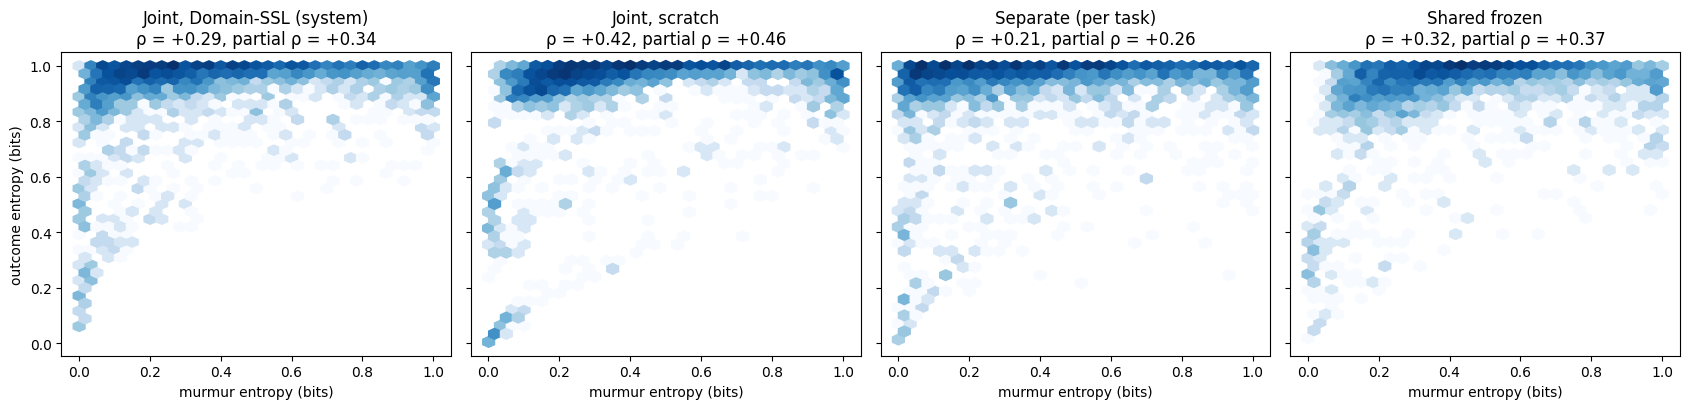

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharex=True, sharey=True)
for ax, model in zip(axes, MODELS):
    a, b = R_UNC[(model, "murmur")]["H_ens_temp"], R_UNC[(model, "outcome")]["H_ens_temp"]
    hb = ax.hexbin(a, b, gridsize=30, cmap="Blues", mincnt=1, bins="log")
    r = prim[(prim.model == model) & (prim.level == "recording") & (prim.subset == "all")].iloc[0]
    ax.set(title=f"{MODEL_NAME[model]}\nρ = {r.spearman:+.2f}, partial ρ = {r.partial:+.2f}", xlabel="murmur entropy (bits)")
axes[0].set_ylabel("outcome entropy (bits)")
plt.tight_layout(); plt.savefig(FIG_DIR / "rq3_uncertainty_scatter.png", dpi=200); plt.show()

## 9. Analysis 2 — does *sharing* cause the coupling?

*Components: ③ multi-task heads (the variable), ② SSL as a secondary variable.*

The question is the paired difference in ρ (primary measure, both raw and partial) between models on the same resamples:

| comparison | isolates |
|---|---|
| Joint Domain-SSL − Separate | **sharing the encoder** (same start, recipe, folds, seeds) |
| Joint Domain-SSL − Shared frozen | training the shared encoder on the tasks vs leaving it fixed |
| Joint Domain-SSL − Joint scratch | the pretraining's effect on coupling |
| Joint scratch − Separate | sharing, without pretraining |

A CI that excludes 0 marks a clear difference.

level                                                                         patient                recording
comparison                                       correlation                                                  
Joint, Domain-SSL (system) − Joint, scratch      partial      -0.152 [-0.201, -0.101]  -0.125 [-0.161, -0.088]
                                                 raw          -0.155 [-0.204, -0.106]  -0.131 [-0.167, -0.094]
Joint, Domain-SSL (system) − Separate (per task) partial      +0.031 [-0.017, +0.076]  +0.072 [+0.036, +0.107]
                                                 raw          +0.039 [-0.006, +0.082]  +0.086 [+0.051, +0.121]
Joint, Domain-SSL (system) − Shared frozen       partial      -0.014 [-0.074, +0.049]  -0.037 [-0.077, +0.003]
                                                 raw          +0.019 [-0.041, +0.076]  -0.029 [-0.073, +0.013]
Joint, scratch − Separate (per task)             partial      +0.183 [+0.126, +0.237]  +0.197 [+0.160, +0.233]
                                                 raw          +0.194 [+0.140, +0.247]  +0.217 [+0.175, +0.253]

level                                                                     patient            recording
comparison                                       correlation                                          
Joint, Domain-SSL (system) − Joint, scratch      partial           B more coupled       B more coupled
                                                 raw               B more coupled       B more coupled
Joint, Domain-SSL (system) − Separate (per task) partial      no clear difference       A more coupled
                                                 raw          no clear difference       A more coupled
Joint, Domain-SSL (system) − Shared frozen       partial      no clear difference  no clear difference
                                                 raw          no clear difference  no clear difference
Joint, scratch − Separate (per task)             partial           A more coupled       A more coupled
                                                 raw               A more coupled       A more coupled

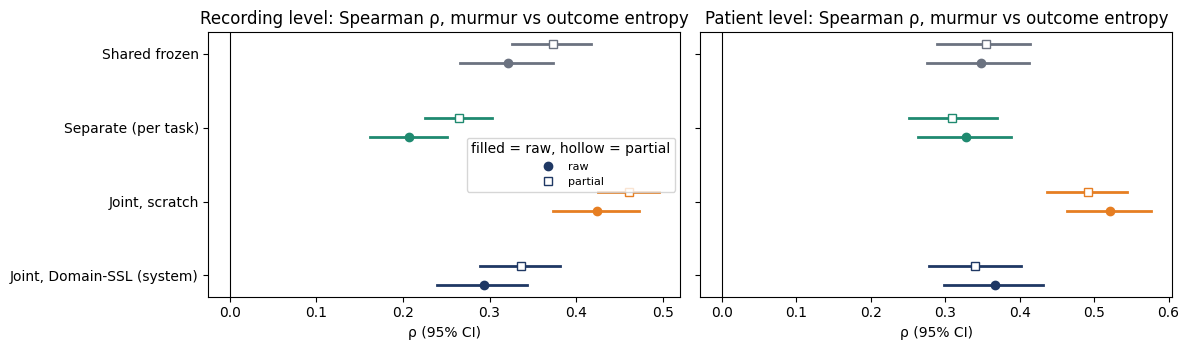

In [12]:
PAIRS = [("joint_domain", "separate"), ("joint_domain", "frozen_shared"), ("joint_domain", "joint_scratch"), ("joint_scratch", "separate")]
cdiff_rows = []
for a_, b_ in PAIRS:
    for lvl in LEVEL:
        for sub in SUBSETS[lvl]:
            for kind in ["raw", "partial"]:
                key = lambda m: (m, lvl, sub, "H_ens_temp", kind)
                d = CBOOT[key(a_)] - CBOOT[key(b_)]
                pa = prim[(prim.model == a_) & (prim.level == lvl) & (prim.subset == sub)].iloc[0]
                pb = prim[(prim.model == b_) & (prim.level == lvl) & (prim.subset == sub)].iloc[0]
                col = "spearman" if kind == "raw" else "partial"
                lo, hi = np.percentile(d, [2.5, 97.5])
                cdiff_rows.append({"comparison": f"{MODEL_NAME[a_]} − {MODEL_NAME[b_]}", "level": lvl, "subset": sub, "correlation": kind,
                                   "difference": pa[col] - pb[col], "ci_low": lo, "ci_high": hi,
                                   "verdict": "A more coupled" if lo > 0 else ("B more coupled" if hi < 0 else "no clear difference")})
cdiff = pd.DataFrame(cdiff_rows)
cdiff["Δρ (95% CI)"] = [fmt3(r.difference, r.ci_low, r.ci_high) for r in cdiff.itertuples()]
display(cdiff[cdiff.subset == "all"].pivot_table(index=["comparison", "correlation"], columns="level", values="Δρ (95% CI)", aggfunc="first"))
display(cdiff[cdiff.subset == "all"].pivot_table(index=["comparison", "correlation"], columns="level", values="verdict", aggfunc="first"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, lvl in zip(axes, ["recording", "patient"]):
    for i, model in enumerate(MODELS):
        for j, (kind, mk) in enumerate([("raw", "o"), ("partial", "s")]):
            r = prim[(prim.model == model) & (prim.level == lvl) & (prim.subset == "all")].iloc[0]
            col = "spearman" if kind == "raw" else "partial"
            yv = i + (j - 0.5) * 0.25
            ax.plot([r[col + "_lo"], r[col + "_hi"]], [yv, yv], color=MODEL_COLOR[model], lw=2)
            ax.plot(r[col], yv, mk, color=MODEL_COLOR[model], mfc="white" if kind == "partial" else MODEL_COLOR[model], ms=6,
                    label=kind if i == 0 else None)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(range(len(MODELS))); ax.set_yticklabels([MODEL_NAME[m] for m in MODELS])
    ax.set(title=f"{lvl.capitalize()} level: Spearman ρ, murmur vs outcome entropy", xlabel="ρ (95% CI)")
axes[0].legend(title="filled = raw, hollow = partial", fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "rq3_correlations.png", dpi=200); plt.show()

## 10. Analysis 3 — does confidence on one task predict reliability on the other?

*Components: ③ × ④. This is the methods document's question, taken literally.*

For each model, the primary uncertainty of one head is used as a score to detect **errors of the other head**. Errors come from the temperature-scaled ensemble's decisions at the validation thresholds.

| AUROC | meaning |
|---|---|
| murmur uncertainty → murmur errors | within-task reliability (reference) |
| outcome uncertainty → outcome errors | within-task reliability (reference) |
| **murmur uncertainty → outcome errors** | cross-task: does murmur doubt warn about outcome mistakes? |
| **outcome uncertainty → murmur errors** | cross-task, the other way |

AUROC 0.5 = no information. Patient level is primary (decisions are per patient); recording level is secondary. Murmur errors exclude Unknown-murmur patients.

In [13]:
def auroc(score, err):
    ok = ~np.isnan(err)
    s, e = score[ok], err[ok]
    return roc_auc_score(e, s) if 0 < e.sum() < len(e) else np.nan

auc_rows = []
for model in tqdm(MODELS, desc="cross-task AUROC"):
    for lvl in ["patient", "recording"]:
        unc = LEVEL[lvl]["unc"]
        err = {t: decisions(model, t, lvl)[1] for t in TASKS}
        idx_sets = BI[(lvl, "all")]
        for src in TASKS:
            for tgt in TASKS:
                s, e = unc[(model, src)]["H_ens_temp"], err[tgt]
                bs = np.array([auroc(s[b], e[b]) for b in idx_sets])
                auc_rows.append({"model": model, "level": lvl, "uncertainty_of": src, "errors_of": tgt,
                                 "kind": "within-task" if src == tgt else "cross-task", "auroc": auroc(s, e),
                                 "ci_low": np.nanpercentile(bs, 2.5), "ci_high": np.nanpercentile(bs, 97.5),
                                 "n_errors": int(np.nansum(e)), "n": int((~np.isnan(e)).sum())})
aucs = pd.DataFrame(auc_rows)
aucs["model_name"] = aucs.model.map(MODEL_NAME)
aucs["AUROC (95% CI)"] = [f"{r.auroc:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]" for r in aucs.itertuples()]
aucs["score → errors"] = aucs.uncertainty_of + " unc. → " + aucs.errors_of + " errors"
for lvl in ["patient", "recording"]:
    print(f"\n=== {lvl} level ===")
    display(aucs[aucs.level == lvl].pivot_table(index="model_name", columns="score → errors", values="AUROC (95% CI)", aggfunc="first"))

cross-task AUROC:   0%|          | 0/4 [00:00<?, ?it/s]


=== patient level ===


score → errors,murmur unc. → murmur errors,murmur unc. → outcome errors,outcome unc. → murmur errors,outcome unc. → outcome errors
model_name,,,,
"Joint, Domain-SSL (system)","0.817 [0.758, 0.871]","0.567 [0.533, 0.604]","0.622 [0.562, 0.684]","0.655 [0.621, 0.688]"
"Joint, scratch","0.879 [0.841, 0.914]","0.561 [0.524, 0.595]","0.668 [0.616, 0.718]","0.609 [0.574, 0.644]"
Separate (per task),"0.856 [0.806, 0.899]","0.547 [0.509, 0.583]","0.648 [0.594, 0.700]","0.631 [0.593, 0.667]"
Shared frozen,"0.806 [0.773, 0.835]","0.541 [0.507, 0.576]","0.598 [0.556, 0.643]","0.610 [0.574, 0.647]"



=== recording level ===


score → errors,murmur unc. → murmur errors,murmur unc. → outcome errors,outcome unc. → murmur errors,outcome unc. → outcome errors
model_name,,,,
"Joint, Domain-SSL (system)","0.807 [0.771, 0.840]","0.507 [0.479, 0.536]","0.627 [0.592, 0.663]","0.655 [0.627, 0.686]"
"Joint, scratch","0.836 [0.802, 0.865]","0.525 [0.494, 0.555]","0.639 [0.598, 0.676]","0.619 [0.591, 0.648]"
Separate (per task),"0.815 [0.777, 0.850]","0.498 [0.471, 0.525]","0.587 [0.551, 0.621]","0.636 [0.605, 0.666]"
Shared frozen,"0.785 [0.750, 0.818]","0.496 [0.467, 0.524]","0.588 [0.552, 0.625]","0.617 [0.587, 0.647]"


## 11. Analysis 4 — failure modes: confident on one task, uncertain on the other

*Components: ③ × ④. The methods document's failure-mode analysis.*

Each task's primary uncertainty is split into **thirds** (cut-points from that model's own distribution): **confident** (lowest third), **middle**, **uncertain** (highest third). Splitting each model by its own thirds keeps the comparison fair even though the models' calibration differs. RQ6 repeats this check with the real confidence gates.

1. **3 × 3 table** of murmur third × outcome third, as the observed/expected ratio. If the tasks were independent, every cell would hold 1/9 of patients (ratio 1). Coupling fills the diagonal and empties the discordant corners.
2. **Discordant cells:** *confident murmur & uncertain outcome*, and *uncertain murmur & confident outcome*, with bootstrap CIs on the observed/expected ratio.
3. **Is the confident task still right when the other is uncertain?** Accuracy of the confident task in the discordant cell vs in the *both confident* cell, with the difference's CI.

Patient level is primary, recording level secondary. Unknown-murmur patients count in the table but not in murmur accuracy. Cut-points are fixed on the full data and not re-estimated inside the bootstrap.


=== patient level ===


model_name,"Joint, Domain-SSL (system)","Joint, scratch",Separate (per task),Shared frozen
quantity,,,,
chi2 p-value (independence),2.1e-23,1e-46,6.7e-16,1.6e-22
murmur acc drop,"0.049 [-0.006, 0.123]","0.033 [-0.021, 0.134]","0.047 [-0.007, 0.116]","0.010 [-0.025, 0.061]"
murmur acc | other confident,"0.994 [0.981, 1.000]","0.990 [0.974, 1.000]","0.994 [0.979, 1.000]","0.988 [0.969, 1.000]"
murmur acc | other uncertain,"0.945 [0.875, 1.000]","0.957 [0.857, 1.000]","0.946 [0.878, 1.000]","0.978 [0.927, 1.000]"
n discordant: conf-murmur & unc-outcome,57,25,57,50
n discordant: unc-murmur & conf-outcome,55,46,70,72
outcome acc drop,"0.119 [-0.014, 0.262]","0.120 [-0.029, 0.266]","0.110 [-0.022, 0.236]","0.008 [-0.109, 0.131]"
outcome acc | other confident,"0.792 [0.726, 0.851]","0.772 [0.716, 0.827]","0.767 [0.695, 0.827]","0.744 [0.679, 0.808]"
outcome acc | other uncertain,"0.673 [0.543, 0.794]","0.652 [0.512, 0.794]","0.657 [0.536, 0.768]","0.736 [0.620, 0.835]"



=== recording level ===


model_name,"Joint, Domain-SSL (system)","Joint, scratch",Separate (per task),Shared frozen
quantity,,,,
chi2 p-value (independence),4.8e-54,3.7e-114,1.4e-25,3.7e-88
murmur acc drop,"0.003 [-0.032, 0.045]","0.005 [-0.017, 0.035]","0.016 [-0.005, 0.039]","0.042 [0.001, 0.087]"
murmur acc | other confident,"0.971 [0.954, 0.987]","0.988 [0.978, 0.997]","0.987 [0.974, 0.998]","0.977 [0.960, 0.991]"
murmur acc | other uncertain,"0.969 [0.929, 0.995]","0.983 [0.954, 1.000]","0.971 [0.948, 0.992]","0.935 [0.892, 0.972]"
n discordant: conf-murmur & unc-outcome,198,117,243,155
n discordant: unc-murmur & conf-outcome,258,206,301,253
outcome acc drop,"-0.045 [-0.129, 0.041]","-0.061 [-0.146, 0.020]","-0.023 [-0.099, 0.048]","-0.093 [-0.173, -0.011]"
outcome acc | other confident,"0.730 [0.670, 0.786]","0.701 [0.647, 0.753]","0.727 [0.667, 0.780]","0.697 [0.642, 0.752]"
outcome acc | other uncertain,"0.775 [0.703, 0.840]","0.762 [0.687, 0.829]","0.751 [0.693, 0.806]","0.791 [0.720, 0.852]"


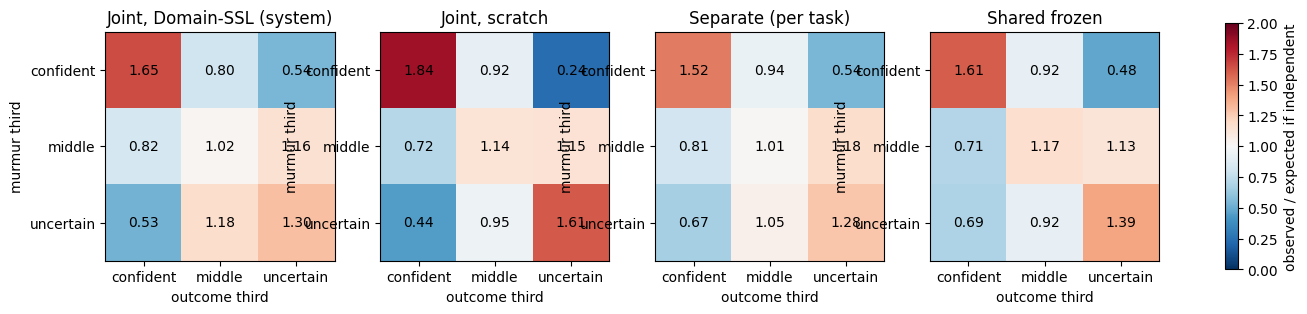

In [14]:
def thirds(v):
    lo, hi = np.quantile(v, [1 / 3, 2 / 3])
    return np.where(v <= lo, 0, np.where(v >= hi, 2, 1))      # 0 confident, 1 middle, 2 uncertain

fm_rows, tab_rows, FM = [], [], {}
for model in MODELS:
    for lvl in ["patient", "recording"]:
        unc = LEVEL[lvl]["unc"]
        tm, to = thirds(unc[(model, "murmur")]["H_ens_temp"]), thirds(unc[(model, "outcome")]["H_ens_temp"])
        err_m, err_o = decisions(model, "murmur", lvl)[1], decisions(model, "outcome", lvl)[1]
        n = len(tm)
        obs = np.array([[np.mean((tm == i) & (to == j)) for j in range(3)] for i in range(3)])
        exp = np.outer([np.mean(tm == i) for i in range(3)], [np.mean(to == j) for j in range(3)])
        FM[(model, lvl)] = obs / exp
        chi2, pval = chi2_contingency(np.round(obs * n))[:2]
        for i in range(3):
            for j in range(3):
                tab_rows.append({"model": model, "level": lvl, "murmur_third": ["confident", "middle", "uncertain"][i],
                                 "outcome_third": ["confident", "middle", "uncertain"][j], "share": obs[i, j], "obs_over_exp": obs[i, j] / exp[i, j]})

        def stats(ix):
            t_m, t_o, e_m, e_o = tm[ix], to[ix], err_m[ix], err_o[ix]
            r = lambda a, b: np.mean((t_m == a) & (t_o == b)) / (np.mean(t_m == a) * np.mean(t_o == b))
            acc = lambda e, mask: 1 - np.nanmean(e[mask]) if (~np.isnan(e[mask])).sum() > 0 else np.nan
            return {"ratio conf-murmur & unc-outcome": r(0, 2), "ratio unc-murmur & conf-outcome": r(2, 0),
                    "ratio both confident": r(0, 0), "ratio both uncertain": r(2, 2),
                    "murmur acc | other uncertain": acc(e_m, (t_m == 0) & (t_o == 2)),
                    "murmur acc | other confident": acc(e_m, (t_m == 0) & (t_o == 0)),
                    "outcome acc | other uncertain": acc(e_o, (t_o == 0) & (t_m == 2)),
                    "outcome acc | other confident": acc(e_o, (t_o == 0) & (t_m == 0))}
        point = stats(np.arange(n))
        point["murmur acc drop"] = point["murmur acc | other confident"] - point["murmur acc | other uncertain"]
        point["outcome acc drop"] = point["outcome acc | other confident"] - point["outcome acc | other uncertain"]
        bs = []
        for b in BI[(lvl, "all")]:
            s = stats(b)
            s["murmur acc drop"] = s["murmur acc | other confident"] - s["murmur acc | other uncertain"]
            s["outcome acc drop"] = s["outcome acc | other confident"] - s["outcome acc | other uncertain"]
            bs.append(s)
        for k, v in point.items():
            arr = np.array([d[k] for d in bs], dtype=float)
            fm_rows.append({"model": model, "level": lvl, "quantity": k, "value": v,
                            "ci_low": np.nanpercentile(arr, 2.5), "ci_high": np.nanpercentile(arr, 97.5)})
        fm_rows.append({"model": model, "level": lvl, "quantity": "chi2 p-value (independence)", "value": pval, "ci_low": np.nan, "ci_high": np.nan})
        fm_rows.append({"model": model, "level": lvl, "quantity": "n discordant: conf-murmur & unc-outcome", "value": int(np.sum((tm == 0) & (to == 2))), "ci_low": np.nan, "ci_high": np.nan})
        fm_rows.append({"model": model, "level": lvl, "quantity": "n discordant: unc-murmur & conf-outcome", "value": int(np.sum((tm == 2) & (to == 0))), "ci_low": np.nan, "ci_high": np.nan})
fm = pd.DataFrame(fm_rows)
fm["model_name"] = fm.model.map(MODEL_NAME)
fm["value (95% CI)"] = [f"{r.value:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]" if not np.isnan(r.ci_low) else
                        (f"{r.value:.2g}" if "p-value" in r.quantity else f"{r.value:.0f}") for r in fm.itertuples()]
fm_tables = pd.DataFrame(tab_rows)
for lvl in ["patient", "recording"]:
    print(f"\n=== {lvl} level ===")
    display(fm[fm.level == lvl].pivot_table(index="quantity", columns="model_name", values="value (95% CI)", aggfunc="first"))

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
labs = ["confident", "middle", "uncertain"]
for ax, model in zip(axes, MODELS):
    M = FM[(model, "patient")]
    im = ax.imshow(M, cmap="RdBu_r", vmin=0, vmax=2)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=10)
    ax.set_xticks(range(3)); ax.set_xticklabels(labs); ax.set_yticks(range(3)); ax.set_yticklabels(labs)
    ax.set(title=MODEL_NAME[model], xlabel="outcome third", ylabel="murmur third")
fig.colorbar(im, ax=axes, shrink=0.8, label="observed / expected if independent")
plt.savefig(FIG_DIR / "rq3_failure_modes.png", dpi=200, bbox_inches="tight"); plt.show()

## 12. Analysis 5 — does joint training cost accuracy or calibration?

*Components: ③ multi-task heads; ② SSL; ④ every UQ method.*

The same metrics as RQ2 for every model, task and UQ method:
- **patient level:** F1 (macro), Accuracy, Weighted accuracy, AUC, c_outcome;
- **recording level:** AUC, ECE, Brier, log-loss.

These are followed by paired differences. **Joint Domain-SSL − Separate** is RQ6's "− multi-task" comparison, and **Joint Domain-SSL − Joint scratch** is its "− SSL" comparison. Lower is better for cost, ECE, Brier and log-loss.

In [15]:
def ece_binary(y, p, n_bins=10):
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return sum(np.mean(bins == b) * abs(y[bins == b].mean() - p[bins == b].mean()) for b in range(n_bins) if np.any(bins == b))

def patient_metrics(y, p, yhat, task):
    out = {"F1 (macro)": f1_score(y, yhat, average="macro"), "Accuracy": accuracy_score(y, yhat),
           "Weighted accuracy": weighted_accuracy(y, yhat), "AUC": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan}
    if task == "outcome":
        out["Cost (c_outcome)"] = c_outcome(y, yhat)
    return out

def recording_metrics(y, p):
    return {"AUC": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan, "ECE": ece_binary(y, p),
            "Brier": np.mean((p - y) ** 2), "Log-loss": logloss(y, p)}

EVAL_PAT = {t: np.where(PLABEL[t] >= 0)[0] for t in TASKS}
EVAL_REC = {t: np.where(LABEL[t] >= 0)[0] for t in TASKS}
BI_PAT = {t: boot_index_sets(PAT.group.values[EVAL_PAT[t]]) for t in TASKS}
BI_REC = {t: boot_index_sets(man.group.values[EVAL_REC[t]]) for t in TASKS}

res_rows, BOOT = [], {}
for model in tqdm(MODELS, desc="performance bootstrap"):
    for task in TASKS:
        for m in METHODS:
            ip = EVAL_PAT[task]; y = PLABEL[task][ip]; p = PATP[(model, task, m)][ip]
            yhat = (p >= np.array([THR[(model, task, m, f)] for f in PAT.fold.values[ip]])).astype(int)
            point = patient_metrics(y, p, yhat, task)
            bs = [patient_metrics(y[b], p[b], yhat[b], task) for b in BI_PAT[task]]
            for k, v in point.items():
                arr = np.array([d[k] for d in bs]); BOOT[(model, task, m, "patient", k)] = arr
                res_rows.append({"model": model, "task": task, "method": m, "level": "patient", "metric": k, "value": v,
                                 "ci_low": np.nanpercentile(arr, 2.5), "ci_high": np.nanpercentile(arr, 97.5)})
            ir = EVAL_REC[task]; y = LABEL[task][ir]; p = OOF[(model, task, m)][ir]
            point = recording_metrics(y, p)
            bs = [recording_metrics(y[b], p[b]) for b in BI_REC[task]]
            for k, v in point.items():
                arr = np.array([d[k] for d in bs]); BOOT[(model, task, m, "recording", k)] = arr
                res_rows.append({"model": model, "task": task, "method": m, "level": "recording", "metric": k, "value": v,
                                 "ci_low": np.nanpercentile(arr, 2.5), "ci_high": np.nanpercentile(arr, 97.5)})
results = pd.DataFrame(res_rows)
POINT = {(r.model, r.task, r.method, r.level, r.metric): r.value for r in results.itertuples()}
fmtv = lambda r: f"{r.value:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]" if r.metric != "Cost (c_outcome)" else f"{r.value:,.0f} [{r.ci_low:,.0f}, {r.ci_high:,.0f}]"
results["value (95% CI)"] = results.apply(fmtv, axis=1)
results["model_name"] = results.model.map(MODEL_NAME)
for task in TASKS:
    for level in ["patient", "recording"]:
        print(f"\n=== {task.upper()} | {level} level | temperature-scaled ensemble ===")
        display(results[(results.task == task) & (results.level == level) & (results.method == "ens_temp")]
                .pivot_table(index="model_name", columns="metric", values="value (95% CI)", aggfunc="first"))

LOWER_BETTER = {"Cost (c_outcome)", "ECE", "Brier", "Log-loss"}
PERF_PAIRS = [("joint_domain", "separate"), ("joint_domain", "joint_scratch"), ("joint_domain", "frozen_shared"), ("joint_scratch", "separate")]
pd_rows = []
for a_, b_ in PERF_PAIRS:
    for (mm, task, m, level, metric), arr in BOOT.items():
        if mm != a_:
            continue
        d = arr - BOOT[(b_, task, m, level, metric)]
        lo, hi = np.nanpercentile(d, [2.5, 97.5])
        better = (hi < 0) if metric in LOWER_BETTER else (lo > 0)
        worse = (lo > 0) if metric in LOWER_BETTER else (hi < 0)
        pd_rows.append({"comparison": f"{MODEL_NAME[a_]} − {MODEL_NAME[b_]}", "task": task, "method": m, "level": level, "metric": metric,
                        "difference": POINT[(a_, task, m, level, metric)] - POINT[(b_, task, m, level, metric)], "ci_low": lo, "ci_high": hi,
                        "verdict": MODEL_NAME[a_] if better else (MODEL_NAME[b_] if worse else "n.s.")})
perf_diff = pd.DataFrame(pd_rows)
perf_diff["cell"] = perf_diff.apply(lambda r: (f"{r.difference:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]" if r.metric != "Cost (c_outcome)"
                                               else f"{r.difference:+,.0f} [{r.ci_low:+,.0f}, {r.ci_high:+,.0f}]") + f"  → {r.verdict}", axis=1)
for task in TASKS:
    print(f"\n=== {task.upper()}: paired differences, temperature-scaled ensemble ===")
    display(perf_diff[(perf_diff.task == task) & (perf_diff.method == "ens_temp")]
            .pivot_table(index=["comparison", "level"], columns="metric", values="cell", aggfunc="first"))

performance bootstrap:   0%|          | 0/4 [00:00<?, ?it/s]


=== MURMUR | patient level | temperature-scaled ensemble ===


metric,AUC,Accuracy,F1 (macro),Weighted accuracy
model_name,,,,
"Joint, Domain-SSL (system)","0.925 [0.896, 0.954]","0.911 [0.891, 0.929]","0.865 [0.835, 0.893]","0.860 [0.823, 0.894]"
"Joint, scratch","0.933 [0.907, 0.956]","0.868 [0.846, 0.891]","0.818 [0.784, 0.848]","0.852 [0.818, 0.885]"
Separate (per task),"0.931 [0.901, 0.958]","0.888 [0.866, 0.910]","0.841 [0.811, 0.871]","0.868 [0.832, 0.901]"
Shared frozen,"0.885 [0.849, 0.919]","0.796 [0.768, 0.824]","0.737 [0.702, 0.770]","0.790 [0.753, 0.825]"



=== MURMUR | recording level | temperature-scaled ensemble ===


metric,AUC,Brier,ECE,Log-loss
model_name,,,,
"Joint, Domain-SSL (system)","0.896 [0.867, 0.924]","0.072 [0.060, 0.086]","0.029 [0.020, 0.043]","0.265 [0.224, 0.309]"
"Joint, scratch","0.906 [0.882, 0.930]","0.073 [0.060, 0.086]","0.015 [0.011, 0.031]","0.257 [0.220, 0.298]"
Separate (per task),"0.903 [0.875, 0.927]","0.073 [0.060, 0.085]","0.026 [0.019, 0.039]","0.264 [0.225, 0.305]"
Shared frozen,"0.868 [0.836, 0.897]","0.088 [0.074, 0.104]","0.031 [0.022, 0.050]","0.304 [0.262, 0.351]"



=== OUTCOME | patient level | temperature-scaled ensemble ===


... (3 outputs left out)


=== MURMUR: paired differences, temperature-scaled ensemble ===


metric                                                                                                    AUC                                           Accuracy                                              Brier  \
comparison                                       level                                                                                                                                                                
Joint, Domain-SSL (system) − Joint, scratch      patient                      -0.008 [-0.021, +0.004]  → n.s.  +0.042 [+0.024, +0.061]  → Joint, Domain-SSL (...                                                NaN   
                                                 recording                    -0.010 [-0.022, +0.001]  → n.s.                                                NaN                    -0.001 [-0.003, +0.002]  → n.s.   
Joint, Domain-SSL (system) − Separate (per task) patient                      -0.006 [-0.019, +0.008]  → n.s.  +0.023 [+0.007, +0.040]  → Joint, Domain-SSL (...                                                NaN   
                                                 recording                    -0.006 [-0.017, +0.004]  → n.s.                                                NaN                    -0.000 [-0.003, +0.003]  → n.s.   
Joint, Domain-SSL (system) − Shared frozen       patient    +0.040 [+0.022, +0.060]  → Joint, Domain-SSL (...  +0.114 [+0.091, +0.138]  → Joint, Domain-SSL (...                                                NaN   
                                                 recording  +0.028 [+0.014, +0.044]  → Joint, Domain-SSL (...                                                NaN  -0.016 [-0.021, -0.011]  → Joint, Domain-SSL (...   
Joint, scratch − Separate (per task)             patient                      +0.002 [-0.011, +0.016]  → n.s.                    -0.019 [-0.040, +0.000]  → n.s.                                                NaN   
                                                 recording                    +0.004 [-0.008, +0.016]  → n.s.                                                NaN                    +0.001 [-0.003, +0.004]  → n.s.   

metric                                                                                            ECE                                         F1 (macro)                                           Log-loss  \
comparison                                       level                                                                                                                                                        
Joint, Domain-SSL (system) − Joint, scratch      patient                                          NaN  +0.047 [+0.023, +0.071]  → Joint, Domain-SSL (...                                                NaN   
                                                 recording  +0.014 [+0.000, +0.022]  → Joint, scratch                                                NaN                    +0.007 [-0.003, +0.018]  → n.s.   
Joint, Domain-SSL (system) − Separate (per task) patient                                          NaN  +0.024 [+0.002, +0.045]  → Joint, Domain-SSL (...                                                NaN   
                                                 recording            +0.003 [-0.008, +0.014]  → n.s.                                                NaN                    +0.001 [-0.010, +0.013]  → n.s.   
Joint, Domain-SSL (system) − Shared frozen       patient                                          NaN  +0.128 [+0.100, +0.155]  → Joint, Domain-SSL (...                                                NaN   
                                                 recording            -0.002 [-0.015, +0.008]  → n.s.                                                NaN  -0.040 [-0.057, -0.024]  → Joint, Domain-SSL (...   
Joint, scratch − Separate (per task)             patient                                          NaN                    -0.023 [-0.050, +0.002]  → n.s.                                         


=== OUTCOME: paired differences, temperature-scaled ensemble ===


metric                                                                                            AUC                         Accuracy                                      Brier  \
comparison                                       level                                                                                                                              
Joint, Domain-SSL (system) − Joint, scratch      patient    -0.021 [-0.037, -0.006]  → Joint, scratch  -0.012 [-0.039, +0.017]  → n.s.                                        NaN   
                                                 recording            -0.013 [-0.027, +0.001]  → n.s.                              NaN  +0.004 [+0.001, +0.007]  → Joint, scratch   
Joint, Domain-SSL (system) − Separate (per task) patient              -0.009 [-0.022, +0.003]  → n.s.  -0.005 [-0.026, +0.017]  → n.s.                                        NaN   
                                                 recording            -0.009 [-0.021, +0.001]  → n.s.                              NaN            -0.001 [-0.003, +0.002]  → n.s.   
Joint, Domain-SSL (system) − Shared frozen       patient              -0.016 [-0.033, +0.001]  → n.s.  -0.015 [-0.043, +0.013]  → n.s.                                        NaN   
                                                 recording            -0.011 [-0.027, +0.006]  → n.s.                              NaN            -0.001 [-0.004, +0.002]  → n.s.   
Joint, scratch − Separate (per task)             patient              +0.012 [-0.006, +0.032]  → n.s.  +0.006 [-0.025, +0.035]  → n.s.                                        NaN   
                                                 recording            +0.003 [-0.013, +0.021]  → n.s.                              NaN  -0.005 [-0.008, -0.001]  → Joint, scratch   

metric                                                                              Cost (c_outcome)                              ECE                       F1 (macro)                                   Log-loss  \
comparison                                       level                                                                                                                                                              
Joint, Domain-SSL (system) − Joint, scratch      patient       +737 [+189, +1,325]  → Joint, scratch                              NaN  -0.004 [-0.034, +0.025]  → n.s.                                        NaN   
                                                 recording                                       NaN  +0.002 [-0.019, +0.020]  → n.s.                              NaN            +0.006 [-0.004, +0.014]  → n.s.   
Joint, Domain-SSL (system) − Separate (per task) patient    +517 [+105, +996]  → Separate (per task)                              NaN  +0.000 [-0.021, +0.023]  → n.s.                                        NaN   
                                                 recording                                       NaN  +0.013 [-0.001, +0.027]  → n.s.                              NaN            -0.003 [-0.010, +0.003]  → n.s.   
Joint, Domain-SSL (system) − Shared frozen       patient                 +483 [-122, +1,085]  → n.s.                              NaN  -0.013 [-0.043, +0.016]  → n.s.                                        NaN   
                                                 recording                                       NaN  +0.014 [-0.003, +0.029]  → n.s.                              NaN            -0.003 [-0.011, +0.004]  → n.s.   
Joint, scratch − Separate (per task)             patient                   -221 [-780, +331]  → n.s.                              NaN  +0.005 [-0.029, +0.036]  → n.s.                                        NaN   
                                                 recording                                       NaN  +0.011 [-0.008, +0.031]  → n.s.                              NaN  -0.009 [-0.017, -0.000]  → Joint, scratch   

metric                                                    

## 13. Training diagnostics: the shared best epoch

*Components: ③. A check on the "one best epoch" decision.*

For each joint unit: the chosen epoch (lowest summed validation loss) against each task's own best epoch, and how much validation loss each task gives up by sharing one epoch. Any unit peaking in the last 5 of 60 epochs is flagged.

,best_epoch,murmur_own_best,outcome_own_best,murmur_loss_given_up,outcome_loss_given_up,at_cap,minutes
model,,,,,,,
joint_domain,3.000,9.889,4.000,0.013,0.001,0,32.952
joint_scratch,28.667,29.778,18.778,0.010,0.011,0,70.383


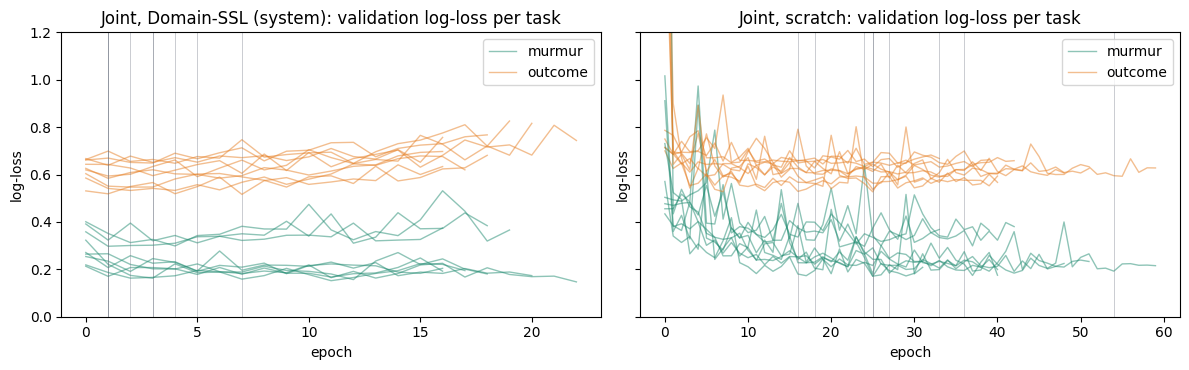

In [16]:
tlog = pd.read_csv(log_path)
tlog["murmur_loss_given_up"] = tlog.val_murmur_at_best - tlog.val_murmur_own_best
tlog["outcome_loss_given_up"] = tlog.val_outcome_at_best - tlog.val_outcome_own_best
tlog["at_cap"] = tlog.best_epoch >= cfg.epochs - 5
display(tlog.groupby("model").agg(best_epoch=("best_epoch", "mean"), murmur_own_best=("murmur_own_best_epoch", "mean"),
                                  outcome_own_best=("outcome_own_best_epoch", "mean"),
                                  murmur_loss_given_up=("murmur_loss_given_up", "mean"), outcome_loss_given_up=("outcome_loss_given_up", "mean"),
                                  at_cap=("at_cap", "sum"), minutes=("minutes", "sum")).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, model in zip(axes, JOINT):
    for f in range(cfg.n_folds):
        for s in cfg.seeds:
            d = np.load(UNIT_DIR / f"{model}_f{f}_s{s}.npz")
            first = (f == 0 and s == cfg.seeds[0])
            ax.plot(d["curve_m"], color=TEAL, alpha=0.5, lw=1, label="murmur" if first else None)
            ax.plot(d["curve_o"], color=ORANGE, alpha=0.5, lw=1, label="outcome" if first else None)
            ax.axvline(int(d["best_epoch"]), color=GRAY, lw=0.5, alpha=0.5)
    ax.set(title=f"{MODEL_NAME[model]}: validation log-loss per task", xlabel="epoch", ylabel="log-loss", ylim=(0, 1.2)); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "rq3_val_curves.png", dpi=200); plt.show()

## 14. Save everything later notebooks need

*Components: all five, by hand-off. RQ4, RQ1, RQ5 and RQ6 load these instead of retraining the system model.*

| file | contents | used by |
|---|---|---|
| `units/joint_*.npz`, `models/joint_*.pt` | both heads' window logits and MC logits, curves; trained joint networks | RQ4, RQ1, RQ5, RQ6 |
| `rq2_folds.csv`, `rq2_windows.csv` | copies of the shared folds and windows | every later RQ |
| `rq3_recording_predictions.csv` | per model × task × recording: probabilities for all 5 UQ methods, all 4 uncertainty measures, `p_good` | RQ4, RQ1, RQ6 |
| `rq3_patient_predictions.csv` | per model × task × method × patient: probability, threshold, decision; patient-level uncertainty | RQ4, RQ6 |
| `rq3_temperatures.csv`, `rq3_thresholds.csv`, `rq3_training_log.csv` | temperatures, patient and recording thresholds, training log | RQ4, RQ6, report |
| `rq3_correlations.csv`, `rq3_coupling_differences.csv`, `rq3_crosstask_auroc.csv`, `rq3_failure_modes.csv`, `rq3_failure_mode_tables.csv` | RQ3's answers | RQ3 report |
| `rq3_performance.csv`, `rq3_performance_differences.csv` | joint vs separate vs scratch vs frozen | RQ3 report, RQ6 |

**Next:** save this version; RQ4 attaches `rq3_outputs`.

In [17]:
rp = []
for model in MODELS:
    for task in TASKS:
        df = man[["wid", "patient_id", "group", "location", "fold", "murmur", "outcome", "p_good"]].copy()
        df.insert(0, "task", task); df.insert(0, "model", model)
        df["y"] = LABEL[task]
        for m in METHODS:
            df[f"p_{m}"] = OOF[(model, task, m)]
        for k, v in R_UNC[(model, task)].items():
            df[k] = v
        rp.append(df)
pd.concat(rp).to_csv(OUT / "rq3_recording_predictions.csv", index=False)

pp = []
for model in MODELS:
    for task in TASKS:
        for m in METHODS:
            df = PAT[["patient_id", "group", "fold", "murmur", "outcome", "p_good"]].copy()
            df.insert(0, "method", m); df.insert(0, "task", task); df.insert(0, "model", model)
            df["y"] = PLABEL[task]
            df["p"] = PATP[(model, task, m)]
            df["threshold"] = [THR[(model, task, m, f)] for f in PAT.fold.values]
            df["pred"] = (df.p >= df.threshold).astype(int)
            if m == "ens_temp":
                for k, v in P_UNC[(model, task)].items():
                    df[k] = v
            pp.append(df)
pd.concat(pp).to_csv(OUT / "rq3_patient_predictions.csv", index=False)

temps.to_csv(OUT / "rq3_temperatures.csv", index=False)
thresholds.to_csv(OUT / "rq3_thresholds.csv", index=False)
corr.drop(columns=["model_name"]).to_csv(OUT / "rq3_correlations.csv", index=False)
cdiff.to_csv(OUT / "rq3_coupling_differences.csv", index=False)
aucs.drop(columns=["model_name"]).to_csv(OUT / "rq3_crosstask_auroc.csv", index=False)
fm.drop(columns=["model_name"]).to_csv(OUT / "rq3_failure_modes.csv", index=False)
fm_tables.to_csv(OUT / "rq3_failure_mode_tables.csv", index=False)
results.drop(columns=["model_name"]).to_csv(OUT / "rq3_performance.csv", index=False)
perf_diff.drop(columns=["cell"]).to_csv(OUT / "rq3_performance_differences.csv", index=False)
json.dump({k: (list(v) if isinstance(v, tuple) else v) for k, v in cfg.__dict__.items()}, open(OUT / "rq3_config.json", "w"), indent=2)

total = sum(f.stat().st_size for f in OUT.rglob("*") if f.is_file()) / 1e6
print(f"saved to {OUT} ({total:.0f} MB):")
for fpath in sorted(OUT.glob("*")):
    print("  ", fpath.name, f"({len(list(fpath.glob('*')))} files)" if fpath.is_dir() else "")

saved to /kaggle/working/rq3_outputs (845 MB):
   figures (4 files)
   models (18 files)
   rq2_folds.csv 
   rq2_windows.csv 
   rq3_config.json 
   rq3_correlations.csv 
   rq3_coupling_differences.csv 
   rq3_crosstask_auroc.csv 
   rq3_failure_mode_tables.csv 
   rq3_failure_modes.csv 
   rq3_patient_predictions.csv 
   rq3_performance.csv 
   rq3_performance_differences.csv 
   rq3_recording_predictions.csv 
   rq3_temperatures.csv 
   rq3_thresholds.csv 
   rq3_training_log.csv 
   units (18 files)
